Successfully loaded 29,651 rows.
Available columns: ['unnamed: 0', 'body', 'department', 'priority', 'tags']
Data cleaning completed successfully!
Data successfully loaded into MySQL database: wessahdb!


C:\Users\wessa\AppData\Local\Temp\ipykernel_27348\325057554.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dept_counts.values, y=dept_counts.index, palette='Blues_r')


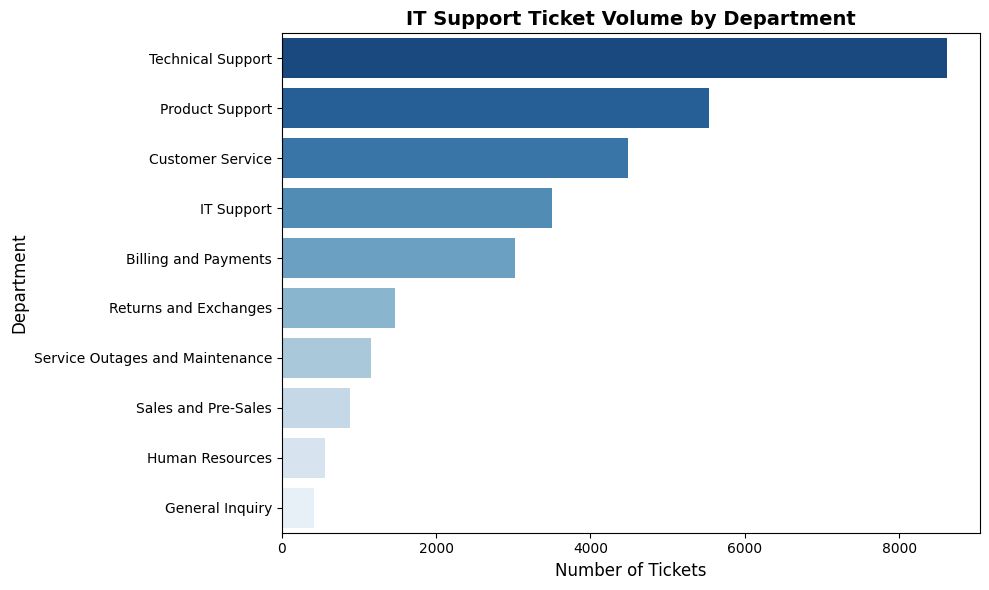

C:\Users\wessa\AppData\Local\Temp\ipykernel_27348\325057554.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=priority_counts.index, y=priority_counts.values, palette='viridis')


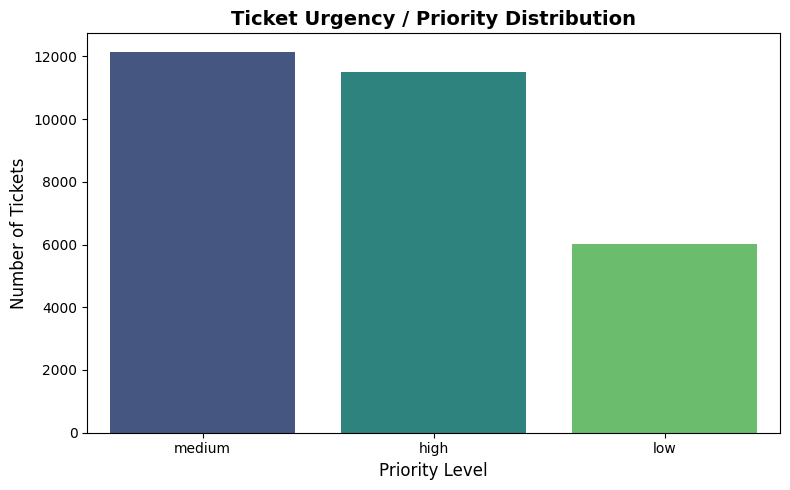

All charts successfully generated and saved to visualizations/!


In [ ]:
# ==========================================
# IT Support Ticket Operational Analytics
# Clean & Secure ETL & Visualization Pipeline
# ==========================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# 1. Ensure working directory is correct and load raw dataset
os.chdir(r"C:\Users\wessa\Desktop\it-support-analytics\notebooks")
file_path = "C:/Users/wessa/Desktop/it-support-analytics/data/itsupportdata.csv"
df = pd.read_csv(file_path)

print(f"Successfully loaded {len(df):,} rows.")

# Standardize column names (converts 'Department' or 'DEPT' to lowercase 'department')
df.columns = df.columns.str.strip().str.lower()
print("Available columns:", df.columns.tolist())

# 2. Basic Data Cleaning & Standardization
df = df.drop_duplicates()

# Fill missing values with safe placeholders (handles columns safely now)
if 'department' in df.columns:
    df['department'] = df['department'].fillna('Unspecified')
if 'priority' in df.columns:
    df['priority'] = df['priority'].fillna('Medium')
if 'tags' in df.columns:
    df['tags'] = df['tags'].fillna('General')

print("Data cleaning completed successfully!")

# 3. Secure Database Connection (Safe for Public GitHub Repos)
db_user = "root"
db_password = os.getenv("SQL PASSWORD HERE", "INSERT PASSWORD HERE")
db_host = "localhost"
db_name = "wessahdb"

# Create database connection engine using PyMySQL
engine = create_engine(f"mysql+pymysql://{db_user}:{db_password}@{db_host}/{db_name}")

# Export DataFrame to MySQL table 'support_tickets'
df.to_sql('support_tickets', con=engine, if_exists='replace', index=False)
print("Data successfully loaded into MySQL database: wessahdb!")

# 4. Generate Chart 1: Departmental Workload Breakdown
if 'department' in df.columns:
    plt.figure(figsize=(10, 6))
    dept_counts = df['department'].value_counts()

    sns.barplot(x=dept_counts.values, y=dept_counts.index, palette='Blues_r')
    plt.title('IT Support Ticket Volume by Department', fontsize=14, fontweight='bold')
    plt.xlabel('Number of Tickets', fontsize=12)
    plt.ylabel('Department', fontsize=12)
    plt.tight_layout()

    plt.savefig('../visualizations/department_breakdown.png', dpi=300)
    plt.show()

# 5. Generate Chart 2: Priority Level Distribution
if 'priority' in df.columns:
    plt.figure(figsize=(8, 5))
    priority_counts = df['priority'].value_counts()

    sns.barplot(x=priority_counts.index, y=priority_counts.values, palette='viridis')
    plt.title('Ticket Urgency / Priority Distribution', fontsize=14, fontweight='bold')
    plt.xlabel('Priority Level', fontsize=12)
    plt.ylabel('Number of Tickets', fontsize=12)
    plt.tight_layout()

    plt.savefig('../visualizations/priority_distribution.png', dpi=300)
    plt.show()

print("All charts successfully generated and saved to visualizations/!")